# <center>VAI Academy</center>


# <center>Análise Exploratória de Dados</center>

___


## Conteúdo
1. [Introdução](#intro) <br>
2. [Sumarização de Dados](#sum) <br>
3. [Visualização de Dados](#dat) <br>
4. [Data Profiling com Pandas](#pan) <br>

<a id="intro"></a>
## 1. Introdução

### Base de dados: Real Estate

Este conjunto de dados será utilizado nesta aula como um exercício em que você poderá aplicar o conhecimento das etapas anteriores. Ao contrário do conjunto de dados `` iris``, aqui você encontrará valores ausentes, outliers e outras inconsistências.

Ao longo deste notebook, você será solicitado a realizar algumas análises para extrair informações valiosas desse conjunto de dados "mais realista", que contém informações sobre propriedades vendidas por uma agência imobiliária.

<center><img src="https://miro.medium.com/max/700/1*-Ly3zdgfNiyrz8RShv9rEA.jpeg" width="300"></center>

<a id="sum"></a>
## 2. Sumarização dos Dados

In [ ]:
# ATENÇÃO:  Após instalar as bibliotecas reinicie o ambiente de execução para garantir que está usando a versão correta
!pip install pandas==1.5.3
!pip install matplotlib==3.7.1
!pip install seaborn==0.12.2

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Exercício 2.1

Carregue a base ```real_estate``` e dê uma olhada nos dados usando as funções acima.

*Dica: Abra o arquivo de dados em um bloco de notas, verifique o formato da base e utilize parâmetros corretos para o carregamento*

In [378]:
# 2.1a. Carregamento do base
real_estate = pd.read_csv("/content/drive/MyDrive/Visagio/6 - Análise Exploratória de Dados/dados/real_estate.csv", sep=';', decimal=',') # Sua resposta aqui

ex2_1a = real_estate.head()
ex2_1a

,DateSold,SaleValue,CommissionValue,Area,PropertyValue,MunicipalTax,RegisterDate,Dorms,Photos,Baths,Sun,Suites,Parking,Type
0,11/09/2015 14:10,590000.0,29500.00,366.00,650000.0,3352.00,24/10/2013 17:18,3.0,26.0,3,Morning,1.0,6,Resale
1,26/06/2015 13:34,470000.0,10420.00,38.00,490000.0,206.00,22/05/2015 18:13,1.0,11.0,1,Morning,0.0,NaN,Resale
2,31/03/2015 16:54,435000.0,24947.25,NaN,NaN,NaN,21/11/2012 18:13,NaN,0.0,NaN,NaN,NaN,NaN,New
3,31/03/2015 15:58,485000.0,20976.25,72.26,NaN,NaN,19/03/2015 14:20,3.0,NaN,1,NaN,1.0,1,New
4,14/08/2015 10:29,380000.0,7815.00,73.00,415000.0,687.27,10/06/2014 17:20,3.0,23.0,1,Afternoon,NaN,1,Resale


In [379]:
# 2.1b. Dimensionalidade da base
ex2_1b = real_estate.shape # Sua resposta aqui

ex2_1b1 = ex2_1b[0]
ex2_1b2 = ex2_1b[1]
ex2_1b

(1852, 14)

In [380]:
# 2.1c. Resumos das informação do DataFrame, como tipo de index, nome das colunas, tipo de dados e quantidade de memória utilizada
ex2_1c  = real_estate.info() # Sua resposta aqui
ex2_1c

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1852 entries, 0 to 1851
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DateSold         1852 non-null   object 
 1   SaleValue        1852 non-null   float64
 2   CommissionValue  1848 non-null   float64
 3   Area             1199 non-null   float64
 4   PropertyValue    1116 non-null   float64
 5   MunicipalTax     1027 non-null   float64
 6   RegisterDate     1852 non-null   object 
 7   Dorms            1167 non-null   float64
 8   Photos           1277 non-null   float64
 9   Baths            1170 non-null   object 
 10  Sun              874 non-null    object 
 11  Suites           712 non-null    float64
 12  Parking          1007 non-null   object 
 13  Type             1852 non-null   object 
dtypes: float64(8), object(6)
memory usage: 202.7+ KB


In [381]:
# 2.1d. Resumo das estatísticas da base (quantidade de valores, média, desvio padrão, min, percentis, max)
ex2_1d = real_estate.describe() # Sua resposta aqui
ex2_1d

,SaleValue,CommissionValue,Area,PropertyValue,MunicipalTax,Dorms,Photos,Suites
count,1.852000e+03,1848.000000,1199.000000,1.116000e+03,1.027000e+03,1167.000000,1277.000000,712.000000
mean,5.233209e+05,23240.573057,156.170442,6.557138e+05,1.761347e+04,2.265638,16.835552,0.793539
std,4.840936e+05,19940.499783,2309.282576,6.455706e+05,4.173683e+05,0.845558,10.775184,0.688105
min,7.815000e+03,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,2.500000e+05,12893.150000,57.000000,2.887500e+05,0.000000e+00,2.000000,15.000000,0.000000
50%,3.900000e+05,18434.690000,73.000000,4.500000e+05,2.000000e+02,2.000000,19.000000,1.000000
75%,6.000000e+05,26880.000000,98.000000,7.900000e+05,8.750000e+02,3.000000,22.000000,1.000000
max,6.000000e+06,260850.000000,80000.000000,6.900000e+06,1.308153e+07,6.000000,73.000000,4.000000


In [382]:
# 2.1e. Verificação da quantidade de valores nulos para cada atributo
ex2_1e = real_estate.isnull().sum() # Sua resposta aqui
ex2_1e

DateSold              0
SaleValue             0
CommissionValue       4
Area                653
PropertyValue       736
MunicipalTax        825
RegisterDate          0
Dorms               685
Photos              575
Baths               682
Sun                 978
Suites             1140
Parking             845
Type                  0
dtype: int64

<a id="dat"></a>

## 3. Visualização de Dados

#### Exercício 3.1

*Nota: Nos exercícios a seguir (e na vida real), pode ser necessário verificar a documentação dos pacotes apresentados acima ou fontes externas, como [StackOverflow](https://stackoverflow.com/).*

Com o conjunto de dados ```real_estate```, plote alguns gráficos para obter algumas informações dos dados.

Quais são as principais conclusões a que podemos chegar nesta análise inicial?

Sinta-se livre para adicionar novas células, se necessário.

In [383]:
# Esse exercício não será considerado na avaliação do notebook
# 3.1. Plote gráficos sobre os dados da real_state


Depois de trabalhar um pouco com os dados, tente responder às perguntas abaixo.

#### Exercício 3.2.1
Qual é a faixa de preço (PropertyValue) em que esta agência imobiliária é especializada?


*dica 1: use histogramas e boxplot e ajuste os eixos para melhor visualização*

*dica 2: considere apenas propriedades com preços maiores que zero*

*dica 3: calcule os limites inferior e superior (whiskers) do boxplot, considere como limite inferior e superior $1,5*IQR$ abaixo do $Q1$ e acima do $Q3$, respectivamente, limitado ao mínimo e máximo da base*

In [384]:
# 3.2.1. Qual é a faixa de preço em que esta agência imobiliária é especializada?
real_estate['PropertyValue']
col_precos = real_estate[real_estate.PropertyValue > 0].PropertyValue

min_value = min(col_precos)
max_value = max(col_precos)

Q1 = col_precos.quantile(.25)
Q3 = col_precos.quantile(.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_inferior = max(limite_inferior, min_value)

limite_superior = Q3 + 1.5 * IQR
limite_superior = min(limite_superior, max_value)

faixa_preco = (limite_inferior, limite_superior)

ex3_2_1a = limite_inferior
ex3_2_1b = limite_superior

faixa_preco

(85000.0, 1540000.0)

#### Exercício 3.2.2
A área da empresa responsável pelo faturamento dos clientes está trabalhando horas extras no final do mês. Há alguma característica na base de dados que explique esse comportamento? Qual é uma possível explicação?

*dica 1: utilize a função* ```to_datetime``` *para lidar com datas*

*dica 2: qual dado da base poderia ser utilizado para representar a quantidade de trabalho do time de faturamento?*

In [385]:
# Faça seus cálculos aqui ou crie novas células que necessitar
real_estate['DateSold'] = pd.to_datetime(real_estate['DateSold'])
real_estate['SoldInEndOfMonth'] = real_estate['DateSold'].dt.day > 20
real_estate['SoldInEndOfMonth'].value_counts()

True     936
False    916
Name: SoldInEndOfMonth, dtype: int64

In [386]:
# 3.2.2. A área da empresa responsável pelo faturamento dos clientes está trabalhando horas extras no final do mês, isso é justificado? Por quê?
ex3_2_2_resposta = 'Sim' # Responda com 'Sim' ou 'Não'
ex3_2_2_justificativa = 'Mais da metade das vendas ocorrem nos últimos 10 dias do mês, o que explica a necessidade de horas extras do time de faturamento' # Texto livre

print(f'[{ex3_2_2_resposta}]: {ex3_2_2_justificativa}')

[Sim]: Mais da metade das vendas ocorrem nos últimos 10 dias do mês, o que explica a necessidade de horas extras do time de faturamento


#### Exercise 3.2.3
A Real Estate Association pede 5% de comissão em cada negócio. Essa porcentagem está sendo respeitada em todos os tipos de propriedade?

*dica: você pode criar uma nova coluna calculada para ajudar a realizar a análise*

In [387]:
# Faça seus cálculos aqui ou crie novas células que necessitar
real_estate['SaleValue'] = pd.to_numeric(real_estate['SaleValue'], errors='coerce')
real_estate['CommissionValue'] = pd.to_numeric(real_estate['CommissionValue'], errors='coerce')

real_estate['ExpectedCommission'] = 0.05 * real_estate['SaleValue']

def compare_commission(row):
    if row['CommissionValue'] == row['ExpectedCommission']:
        return 'Equal'
    elif row['CommissionValue'] > row['ExpectedCommission']:
        return 'Higher'
    else:
        return 'Lower'

real_estate['CommissionComparison'] = real_estate.apply(compare_commission, axis=1)

real_estate[real_estate['Type'].notna()].groupby(['Type', 'CommissionComparison']).size().unstack()

CommissionComparison,Equal,Higher,Lower
Type,,,
New,20,341,373
Resale,140,382,596


In [388]:
# 3.2.3. A porcentagem de comissão está sendo respeitada em todos os tipos de propriedade?
ex3_2_3_resposta = "Não" # Responda com 'Sim' ou 'Não'
ex3_2_3_justificativa = "Apenas 159 vendas tem suas comissões respeitadas. Em alguns casos, as comissões são mais altas, porém, em sua maioria, as comissões são menores do que o valor planejado" # Texto livre

print(f'[{ex3_2_3_resposta}]: {ex3_2_3_justificativa}')

[Não]: Apenas 159 vendas tem suas comissões respeitadas. Em alguns casos, as comissões são mais altas, porém, em sua maioria, as comissões são menores do que o valor planejado


#### Exercício 3.2.4
Quantos dias levam, em média, para vender uma propriedade?

dica 1: primeiro calcule a quantidade de dias entre as datas de *DateSold* e *RegisterDate*, calcule a média, mediana e plote a distribuição

dica 2: não se esqueça de utilizar o formato de data adequado para os atributos [(to_datetime)](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)

dica 3: as métricas devem ser calculadas para intervalos medidos em dias

In [389]:
# Faça seus cálculos aqui ou crie novas células que necessitar
real_estate['DateSold'] = pd.to_datetime(real_estate['DateSold'])
real_estate['RegisterDate'] = pd.to_datetime(real_estate['RegisterDate'])

real_estate['DaysToSell'] = (real_estate['DateSold'] - real_estate['RegisterDate']).dt.days

media_dias = round(real_estate['DaysToSell'].mean())
mediana_dias = round(real_estate['DaysToSell'].median())

print(f'Média de dias para vender uma propriedade: {media_dias} dias')
print(f'Mediana de dias para vender uma propriedade: {mediana_dias} dias')

Média de dias para vender uma propriedade: 244 dias
Mediana de dias para vender uma propriedade: 100 dias


In [390]:
# 3.2.4. Quantos dias levam, em média, para vender uma propriedade?
ex3_2_4_tempo_medio = media_dias # Sua resposta aqui
ex3_2_4_tempo_mediano = mediana_dias # Sua resposta aqui

print(f"Tempo Médio: {ex3_2_4_tempo_medio}")
print(f"Tempo Mediano: {ex3_2_4_tempo_mediano}")

Tempo Médio: 244
Tempo Mediano: 100


#### Exercício 3.2.5
Podemos verificar reduções de preço se a propriedade demorar muito para ser vendida?

*dica: você pode verificar qualquer correlação entre a diferença do preço inicial e do preço vendido e o tempo desde o registro em um gráfico de dispersão, com a diferença de preços e o tempo sendo seus eixos*

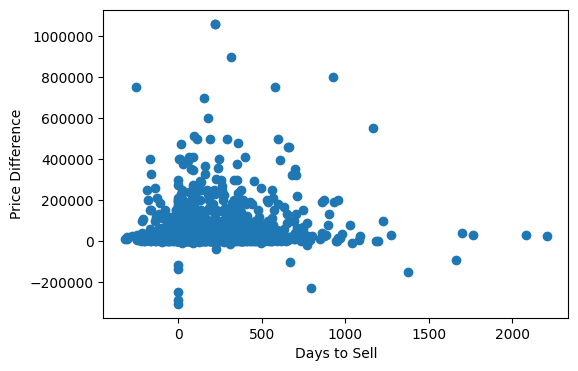

Correlation between Days to Sell and Price Difference: 0.07


In [ ]:
# Faça seus cálculos aqui ou crie novas células que necessitar
real_estate['PriceDifference'] = real_estate['PropertyValue'] - real_estate['SaleValue']
real_estate = real_estate[real_estate['DaysToSell'] <= 40000]
real_estate = real_estate[real_estate['PriceDifference'] <= 2000000]
real_estate = real_estate[real_estate['PriceDifference'] > -500000]

plt.figure(figsize=(6, 4))
plt.scatter(real_estate['DaysToSell'], real_estate['PriceDifference'])
plt.xlabel('Days to Sell')
plt.ylabel('Price Difference')
plt.ticklabel_format(style='plain')
plt.show()
correlation = real_estate['DaysToSell'].corr(real_estate['PriceDifference'])
print(f'Correlation between Days to Sell and Price Difference: {correlation:.2f}')

In [ ]:
# 3.2.5. Podemos verificar reduções de preço se a propriedade demorar muito para ser vendida?
ex3_2_5_resposta = "Não" # Responda com 'Sim' ou 'Não'
ex3_2_5_justificativa = "O preço pode ter reduções independente da quantidade de dias que leva para vender" # Texto livre

print(f'[{ex3_2_5_resposta}]: {ex3_2_5_justificativa}')

[Não]: O preço pode ter reduções independente da quantidade de dias que leva para vender


# Declaração de Inexistência de Plágio:

1. Eu sei que plágio é utilizar o trabalho de outra pessoa e apresentar como meu.
2. Eu sei que plágio é errado e declaro que este notebook foi feito por mim.
3. Tenho consciência de que a utilização do trabalho de terceiros é antiético e está sujeito à medidas administrativas.
4. Declaro também que não compartilhei e não compartilharei meu trabalho com o intuito de que seja copiado e submetido por outra pessoa.

In [ ]:
# LEMBRE-SE DE SALVAR O NOTEBOOK ANTES DE EXECUTAR ESSA CÉLULA

token = '' # seu token aqui

# Não altere o código abaixo
import requests as req
%matplotlib
exec(req.get('https://api.vai.academy/submissioncode2').text)
%matplotlib inline

Using matplotlib backend: agg
Importante: lembre-se de salvar o notebook antes de rodar esta célula!
Executando o seu notebook para a submissão. Isso pode demorar alguns instantes...
>> Verificando exercicios para correção... 
>> Submetendo exercício 2.1a... "Score: 2/2"
>> Submetendo exercício 2.1b... "Score: 1/1"
>> Submetendo exercício 2.1d... "Score: 1/1"
>> Submetendo exercício 2.1e... "Score: 1/1"
>> Submetendo exercício 3.2.1... "Score: 3/3"
>> Submetendo exercício 3.2.2... "Score: 1/1"
>> Submetendo exercício 3.2.3... "Score: 1/1"
>> Submetendo exercício 3.2.4... "Score: 0/2"
>> Submetendo exercício 3.2.5... "Score: 2/2"

Tentativa de submissao #7 / 30
Aluno: Larissa Coelho Ramos
Score: 12 / 14
Parabéns!! Você atingiu os critérios para passar neste notebook.

Pontuação por exercício
Exercicio  Pontuacao Maxima  Pontuacao Obtida
     2.1a                 2                 2
     2.1b                 1                 1
     2.1d                 1                 1
     2.1e     